# 04 · Slice models

Finds the setting of the slice model, one question at a time, on fold 0, then trains it on five folds. Each section ends with key findings.

**Contents**
1. Speed of the 8 candidates
2. Training on part of the series
3. Epochs and learning rate
4. Channels and windows
5. Crop
6. Resolution
7. Backbones
8. Target and loss
9. The two rare writers
10. Five folds

Needs `slices.csv` and `series.csv` (02), `outputs/backbone_benchmark/` from `scripts/benchmark_backbones.py` and `outputs/runs/` from `scripts/train_slice.py`.

No model is trained here. Each section prints the command of its runs; this notebook reads their saved predictions and scores them again.

In [1]:
import functools
import itertools
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

from pe.data.prepare import read_series, read_slices
from pe.metrics import paired_bootstrap, series_losses
from pe.paths import load_paths
from pe.training import learning_rate
from pe.validation import RARE_IN_TEST, predictions, slice_scores, validation_fold

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
PROCESSED, OUTPUTS = paths["processed_data_dir"], paths["outputs_dir"]
RUNS = OUTPUTS / "runs"
DECIDES = "test-like corrected"  # the score that ranks the models (`pe.validation`); lower is better
COLUMNS = [DECIDES, "test-like", "full", "AUROC", "level"]
TO_BEAT, TO_BEAT_FULL = 0.3209, 0.3281  # LightGBM without site, five folds (03)
DEFAULTS = {"fold": 0, "share": 1.0, "seed": 1, "backbone": "efficientnet_b0", "size": 256, "batch": 128, "accumulate": 1, "channels": "-1,0,1", "windows": "pe", "crop": None, "positive_series": False, "without_rare_writers": False, "q_weight": False, "loss": "bce", "series_targets": False,
            "epochs": 4, "lr": 4e-4, "wd": 0.01, "dropout": 0.2, "workers": 12, "stop_when_worse": False, "stop_after": None, "limit": None}  # of scripts/train_slice.py

slices, series = read_slices(PROCESSED / "slices.csv"), read_series(PROCESSED / "series.csv")
fold = validation_fold(slices, series, 0)
print(f"fold 0: {len(fold.y_series):,} series, {fold.test_like.sum():,} test-like, {fold.main.sum():,} main-stack slices")

fold 0: 1,460 series, 1,134 test-like, 355,385 main-stack slices


In [2]:
@functools.cache
def result(run, epoch=None):
    '''The scores of a run at an epoch (the last by default), computed again from its saved logits and checked against its log.'''
    log = pd.read_csv(RUNS / run / "log.csv")
    row = log.iloc[-1] if epoch is None else log[log["epoch"] == epoch].iloc[0]
    logits = np.load(RUNS / run / f"val_logits_e{int(row['epoch'])}.npy")
    scores = slice_scores(fold, logits)
    assert all(np.isclose(scores[key], row[key], atol=1e-6) for key in COLUMNS[:4]), run
    _, corrected, _ = predictions(fold, logits)
    loss, weight = series_losses(fold.y_series, fold.p_series, fold.image_series, fold.y_image, corrected)
    return {**scores, "train loss": row["train loss"], "minutes": row["minutes"], "loss": loss[fold.test_like], "weight": weight[fold.test_like]}


def results(runs):
    '''`result` of a list of runs, each a name or (name, epoch).'''
    return [result(*run) if isinstance(run, tuple) else result(run) for run in runs]


def seeds(name, last=5):
    return [f"{name}_s{seed}" for seed in range(1, last + 1)]


def command(run):
    '''The command of a run: only the arguments that differ from the defaults.'''
    config = json.loads((RUNS / run / "config.json").read_text())
    parts = [f"--{key.replace('_', '-')}" + ("" if value is True else f"={value}" if key == "channels" else f" {value}")
             for key, value in config.items() if key in DEFAULTS and value != DEFAULTS[key]]
    return " ".join(["python scripts/train_slice.py --name", run, *parts])


def compare(groups, reference):
    '''One row per option (a list of seeds): the means over its seeds and the paired series bootstrap of its difference to `reference`.'''
    base = results(reference)
    rows = {}
    for name, runs in groups.items():
        found = results(runs)
        rows[name] = {"seeds": len(found), DECIDES: np.mean([r[DECIDES] for r in found]), "std": np.std([r[DECIDES] for r in found], ddof=1) if len(found) > 1 else np.nan,
                      **{key: np.mean([r[key] for r in found]) for key in COLUMNS[1:]}, "minutes": np.mean([r["minutes"] for r in found]), "difference": ""}
        if runs is not reference:
            d = paired_bootstrap(np.mean([r["loss"] for r in base], axis=0), np.mean([r["loss"] for r in found], axis=0), found[0]["weight"])
            rows[name]["difference"] = f"{d['mean']:+.4f} [{d['low']:+.4f}, {d['high']:+.4f}]"
    return pd.DataFrame(rows).T.astype({"seeds": int, **{key: float for key in [DECIDES, "std", *COLUMNS[1:], "minutes"]}}).round({DECIDES: 4, "std": 4, "test-like": 4, "full": 4, "AUROC": 4, "level": 2, "minutes": 1})


def seed_gap(runs):
    '''The mean absolute gap between the scores of two seeds.'''
    return np.mean([abs(a[DECIDES] - b[DECIDES]) for a, b in itertools.combinations(results(runs), 2)])

## 1. Speed of the 8 candidates

Sections 2–6 screen one setting at a time, so they use the fastest of our 8 candidates. `scripts/benchmark_backbones.py` finds the largest batch of each under 26 GB and its speed on the GPU alone (real steps on random input, no pretrained weights):

In [3]:
speed = pd.concat({size: pd.read_csv(OUTPUTS / "backbone_benchmark" / f"batches_{size}.csv").set_index("name")[["batch", "slices per s"]] for size in (256, 512)}, axis=1)
speed.sort_values((512, "slices per s"), ascending=False)

256                512             
                batch slices per s batch slices per s
name                                                 
efficientnet_b0   384       2471.5   100        637.6
convnext_tiny     276       1425.9    68        393.5
seresnext50       260       1145.0    64        293.6
efficientnet_b4   152        959.6    36        259.3
rexnet_200        192       1104.1    48        258.1
resnest50         260        842.2    64        227.0
mobilevitv2_175   144        872.1    36        219.3
seresnext101      168        733.3    40        193.1

### 1.1 Key findings

- **EfficientNet B0 is the fastest at both sizes (2,472 and 638 slices/s), so it runs every test except the backbone comparison and the final models.** It starts from Noisy Student weights.
- **The data, not the GPU, was the limit at 512 px.** With 12 workers B0 read 405 slices/s from the 512 px store, waiting for data 67% of the time. A store at 256 px (`scripts/build_small_store.py`) gave 1,555 slices/s and no waiting at batch 128 (measured once, not saved).
- **Batch: 128 at 256 px and 32 × 4 at 512 px, for every candidate.** These fit all 8 (the smallest largest batches are 144 and 36) and give the same 128 per optimizer step, so all share one learning rate.

## 2. Training on part of the series

Screening on part of the training series saves time. **Question:** How much score does that cost? 4-epoch schedule, seed 1, validated after every epoch:

In [4]:
stop_runs = {(share, lr): f"s3_p{share}_lr{lr}" for share in (50, 25) for lr in ("4e-4", "2.8e-4")}
print(command(stop_runs[(50, "2.8e-4")]))
rows = [{"series used": f"{share}%", "lr": lr, "epoch": epoch, **{key: result(run, epoch)[key] for key in ["train loss", DECIDES, "AUROC"]}} for (share, lr), run in stop_runs.items() for epoch in (1, 2)]
pd.DataFrame(rows).round(4)

python scripts/train_slice.py --name s3_p50_lr2.8e-4 --share 0.5 --lr 0.00028 --stop-when-worse


,series used,lr,epoch,train loss,test-like corrected,AUROC
0,50%,4e-4,1,0.1057,0.3861,0.8635
1,50%,4e-4,2,0.0427,0.4463,0.8602
2,50%,2.8e-4,1,0.1038,0.3770,0.8610
3,50%,2.8e-4,2,0.0397,0.4421,0.8456
4,25%,4e-4,1,0.1022,0.4446,0.8237
5,25%,4e-4,2,0.0370,0.4756,0.8200
6,25%,2.8e-4,1,0.1011,0.4348,0.8203
7,25%,2.8e-4,2,0.0347,0.4827,0.8194


### 2.1 Key findings

- **We keep 50% of the series.** At epoch 1 it beats 25% by about 0.06 (0.3861 and 0.3770 against 0.4446 and 0.4348).
- **One pass is enough to start memorising.** At epoch 2 the training loss falls and every validation score gets worse, so the model of epoch 1 counts.

## 3. Epochs and learning rate

**Question:** Does a schedule that ends with its learning rate at 0 do better than cutting a longer one? Seed 1, 50% of the series. Fixed before the runs: the 2-epoch schedule wins only if its epoch 2 beats both 1-epoch runs, and the learning rate with the lower score stays.

In [5]:
schedule_runs = {(4, "4e-4"): "s3_p50_lr4e-4", (4, "2.8e-4"): "s3_p50_lr2.8e-4", (2, "4e-4"): "s3b_e2_lr4e-4", (2, "2.8e-4"): "s3b_e2_lr2.8e-4", (1, "4e-4"): "s3b_e1_lr4e-4", (1, "2.8e-4"): "s3b_e1_lr2.8e-4"}
print(command(schedule_runs[(1, "2.8e-4")]))
share_of_peak = lambda epochs: learning_rate(100_000 // epochs, 100_000)  # the learning rate at the end of epoch 1
rows = [{"schedule": f"{epochs}-epoch", "lr": lr, "lr left after epoch 1": f"{share_of_peak(epochs):.0%}", **{key: result(run, 1)[key] for key in ["train loss", DECIDES, "test-like", "AUROC"]}} for (epochs, lr), run in schedule_runs.items()]
print("epoch 2 of the 2-epoch schedules:", {lr: round(result(run, 2)[DECIDES], 4) for (epochs, lr), run in schedule_runs.items() if epochs == 2})
pd.DataFrame(rows).round(4)

python scripts/train_slice.py --name s3b_e1_lr2.8e-4 --share 0.5 --epochs 1 --lr 0.00028


epoch 2 of the 2-epoch schedules: {'4e-4': 0.4561, '2.8e-4': 0.4616}


,schedule,lr,lr left after epoch 1,train loss,test-like corrected,test-like,AUROC
0,4-epoch,4e-4,89%,0.1057,0.3861,0.4788,0.8635
1,4-epoch,2.8e-4,89%,0.1038,0.3770,0.4774,0.8610
2,2-epoch,4e-4,54%,0.1017,0.3979,0.5476,0.8535
3,2-epoch,2.8e-4,54%,0.0987,0.4062,0.5274,0.8566
4,1-epoch,4e-4,0%,0.0925,0.4153,0.5519,0.8554
5,1-epoch,2.8e-4,0%,0.0927,0.4111,0.5198,0.8542


By the rule the 1-epoch schedule with 2.8e-4 wins (0.4111). But the table has an order: the more a model fits inside epoch 1, the worse its validation, and the cut 4-epoch schedule has the best score. So both go on with 5 paired seeds. Fixed before the runs: **B** replaces **A** only if its advantage on the corrected score is more than 2 standard errors of the paired differences.
- **A:** 1-epoch schedule, learning rate down to 0.
- **B:** 4-epoch schedule, stopped after epoch 1.

In [6]:
A = ["s3b_e1_lr2.8e-4", *[f"s2b_A_s{seed}" for seed in range(2, 6)]]
B = [("s3_p50_lr2.8e-4", 1), *[f"s2b_B_s{seed}" for seed in range(2, 6)]]
print(command("s2b_B_s2"))
display(compare({"A": A, "B": B}, reference=A))
paired = pd.DataFrame({key: [b[key] - a[key] for a, b in zip(results(A), results(B))] for key in [DECIDES, "test-like", "AUROC"]}, index=range(1, 6)).rename_axis("B - A, seed")
paired.loc["mean"] = paired.loc[1:5].mean()
paired.loc["|mean| / se"] = paired.loc["mean"].abs() / (paired.loc[1:5].std() / 5 ** 0.5)
print(f"mean absolute gap between two seeds of A: {seed_gap(A):.4f}")
paired.round(4)

python scripts/train_slice.py --name s2b_B_s2 --share 0.5 --seed 2 --lr 0.00028 --stop-after 1


,seeds,test-like corrected,std,test-like,full,AUROC,level,minutes,difference
A,5,0.4205,0.0140,0.5542,0.5916,0.8423,3.63,12.1,
B,5,0.4021,0.0213,0.5068,0.5372,0.8555,3.20,11.5,"-0.0184 [-0.0281, -0.0097]"


mean absolute gap between two seeds of A: 0.0168


,test-like corrected,test-like,AUROC
"B - A, seed",,,
1,-0.0341,-0.0424,0.0068
2,-0.0220,-0.0787,0.0273
3,0.0064,-0.0284,0.0018
4,-0.0418,-0.0630,0.0300
5,-0.0004,-0.0246,-0.0001
mean,-0.0184,-0.0474,0.0132
|mean| / se,1.9669,4.5950,2.0445


### 3.1 Key findings

- **A stays: 1 epoch, learning rate 2.8e-4, mean 0.4205.** B's advantage of 0.0184 is 1.97 standard errors, just below the 2 fixed in advance.
- **This was close.** The raw test-like score (4.6 standard errors) and the AUROC (2.04) favour B, the series bootstrap of the difference excludes 0, and this choice was not tested again later.
- **Two seeds of A differ by 0.0168 on average, which becomes the practical margin of sections 4–6, 8 and 9.** It is a margin, not a significance test.

## 4. Channels and windows

Fixed before the runs, for sections 4–6: every option runs seeds 1–2. If the best beats the 5-seed mean of the current setting by more than 0.0168, it runs seeds 3–5, and it is adopted if its 5-seed mean still does. Otherwise the current setting stays.

**Question:** Which slices and windows should fill the input? Current setting: slices i−1, i, i+1 through the PE window 100/700.

In [7]:
options = {"i-1, i, i+1 / PE (current)": A, "i / PE": seeds("s4_c1", 2), "i-2, i, i+2 / PE": seeds("s4_gap2", 2), "i-2 ... i+2 / PE": seeds("s4_c5", 2),
           "i-1, i, i+1 / mediastinal 40/400": seeds("s5_med", 2), "i / PE, mediastinal, lung": seeds("s5_w3")}
for name in ("s4_c1_s1", "s5_w3_s1"):
    print(command(name))
table = compare(options, reference=A)[[DECIDES, "AUROC"]]
table["better than current"] = (table[DECIDES].iloc[0] - table[DECIDES]).map("{:+.4f}".format)
table.iloc[0, -1] = ""
table

python scripts/train_slice.py --name s4_c1_s1 --share 0.5 --channels=0 --epochs 1 --lr 0.00028
python scripts/train_slice.py --name s5_w3_s1 --share 0.5 --channels=0 --windows pe,mediastinal,lung --epochs 1 --lr 0.00028


,test-like corrected,AUROC,better than current
"i-1, i, i+1 / PE (current)",0.4205,0.8423,
i / PE,0.4116,0.8558,+0.0089
"i-2, i, i+2 / PE",0.4232,0.8398,-0.0027
i-2 ... i+2 / PE,0.4208,0.8436,-0.0003
"i-1, i, i+1 / mediastinal 40/400",0.4388,0.8318,-0.0183
"i / PE, mediastinal, lung",0.3949,0.8579,+0.0256


### 4.1 Key findings

- **Adopted: slice i through three windows (100/700, 40/400, −600/1500), mean 0.3949, 0.0256 better.**
- **More or wider neighbours do not help.** Slice i alone has the lowest mean of the channel options (0.4116), but its 0.0089 is under the margin.
- **The mediastinal window alone is worse** (0.4388).
- The adopted option changes both the slices and the windows, so their effects are not separated.

## 5. Crop

**Question:** Does cutting every slice to the box of its series help? The boxes come from 02. One box per series, 5% added on each side, stretched to a square. Here it means the same 256 px store and input, so the gain cannot come from finer detail.

python scripts/train_slice.py --name s6_lung_s1 --share 0.5 --channels=0 --windows pe,mediastinal,lung --crop lung --epochs 1 --lr 0.00028


,test-like corrected,std,test-like,full,AUROC,difference
no crop (current),0.3949,0.0107,0.5653,0.5892,0.8579,
body box,0.3800,0.0066,0.5082,0.5311,0.8647,"-0.0149 [-0.0248, -0.0051]"
lung box,0.3640,0.0092,0.4765,0.5070,0.8762,"-0.0309 [-0.0464, -0.0156]"


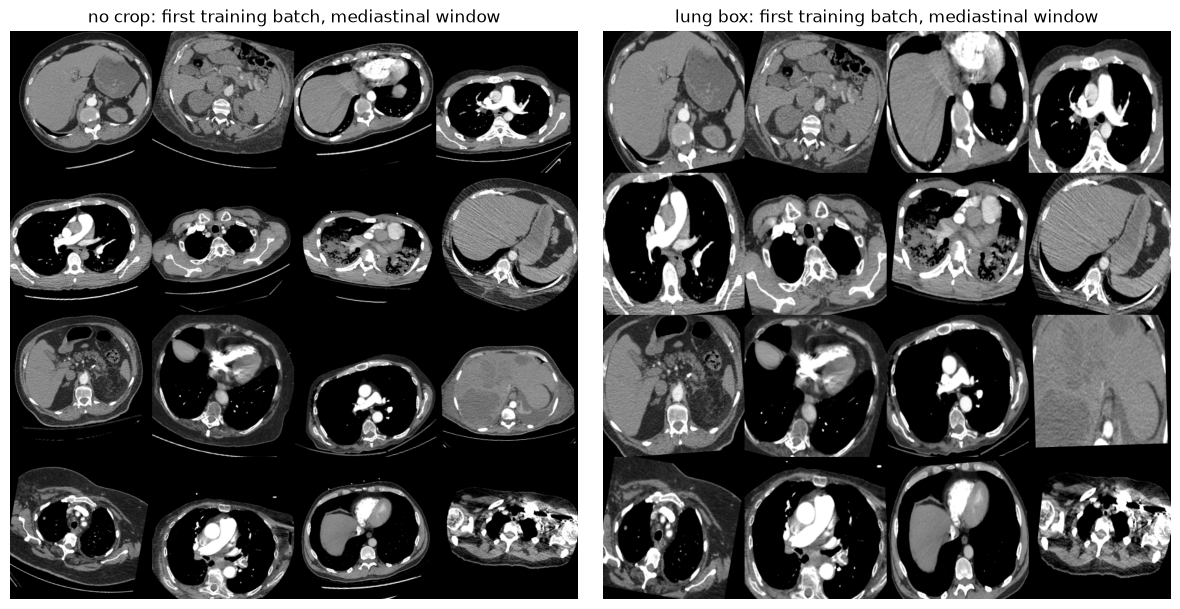

In [8]:
crops = {"no crop (current)": seeds("s5_w3"), "body box": seeds("s6_body", 2), "lung box": seeds("s6_lung")}
print(command("s6_lung_s1"))
display(compare(crops, reference=crops["no crop (current)"]).drop(columns=["seeds", "level", "minutes"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (title, run) in zip(axes, [("no crop", "s5_w3_s1"), ("lung box", "s6_lung_s1")]):
    ax.imshow(plt.imread(RUNS / run / "inputs.png"), cmap="gray")
    ax.set(title=f"{title}: first training batch, mediastinal window")
    ax.axis("off")
plt.tight_layout()

### 5.1 Key findings

- **Adopted: the lung box, mean 0.3640, 0.0309 better.** AUROC rises from 0.858 to 0.876.
- **The body box stays under the margin** (0.3800, 0.0149 better), although its interval excludes 0.

## 6. Resolution

**Question:** How much does the 512 px store give? At 512 px the batch has to be 32 × 4, so BatchNorm sees 32 slices instead of 128. A control at 256 px with the same batch separates the two changes; it cannot be adopted.

In [9]:
sizes = {"256 px, 128 (current)": seeds("s6_lung"), "256 px, 32 x 4 (control)": seeds("s7_256b32", 2), "512 px, 32 x 4": seeds("s7_512")}
print(command("s7_512_s1"))
display(compare(sizes, reference=sizes["256 px, 128 (current)"]).drop(columns=["seeds", "level"]))
print("512 px against the control, seeds 1-2:")
compare({"512 px, 32 x 4": seeds("s7_512", 2)}, reference=sizes["256 px, 32 x 4 (control)"]).drop(columns=["seeds", "level"])

python scripts/train_slice.py --name s7_512_s1 --share 0.5 --size 512 --batch 32 --accumulate 4 --channels=0 --windows pe,mediastinal,lung --crop lung --epochs 1 --lr 0.00028


,test-like corrected,std,test-like,full,AUROC,minutes,difference
"256 px, 128 (current)",0.3640,0.0092,0.4765,0.5070,0.8762,10.2,
"256 px, 32 x 4 (control)",0.3592,0.0114,0.4616,0.4865,0.8833,24.0,"-0.0048 [-0.0126, +0.0032]"
"512 px, 32 x 4",0.3194,0.0023,0.3709,0.3826,0.9311,30.3,"-0.0446 [-0.0576, -0.0320]"


512 px against the control, seeds 1-2:


,test-like corrected,std,test-like,full,AUROC,minutes,difference
"512 px, 32 x 4",0.3178,0.0011,0.3706,0.3836,0.9328,31.0,"-0.0415 [-0.0542, -0.0291]"


### 6.1 Key findings

- **Adopted: 512 px with batch 32 × 4, mean 0.3194, 0.0446 better.** The five seeds lie close together (std 0.0023), and AUROC reaches 0.931.
- **The gain comes from the resolution:** the control scores 0.3592, only 0.0048 better than batch 128, and on the same two seeds 512 px beats the control by 0.0415.
- **It costs 3 times the time:** 30 minutes instead of 10 per run.

## 7. Backbones

**Question:** Which of the 8 candidates go to five folds? From here on the models train on all the series of the training folds, at seed 1. All 8 run at 256 px on a 3-epoch schedule, and the top 3 at 512 px on a 2-epoch schedule:

In [10]:
def backbone_table(prefix, names):
    # The corrected score of epochs 1 and 2, and the other scores of epoch 1
    rows = {}
    for name in names:
        first, second = result(f"{prefix}_{name}_s1", 1), result(f"{prefix}_{name}_s1", 2)
        rows[name] = {"epoch 1": first[DECIDES], "epoch 2": second[DECIDES], **{key: first[key] for key in COLUMNS[1:4]}, "minutes per epoch": first["minutes"]}
    return pd.DataFrame(rows).T.sort_values("epoch 1").round({"epoch 1": 4, "epoch 2": 4, "test-like": 4, "full": 4, "AUROC": 4, "minutes per epoch": 1})


print(command("s8e3_seresnext101_s1"))
print(command("s8e2_512_seresnext101_s1"))
display(backbone_table("s8e3", ["efficientnet_b0", "efficientnet_b4", "seresnext50", "seresnext101", "resnest50", "convnext_tiny", "mobilevitv2_175", "rexnet_200"]).drop(columns="minutes per epoch"))
display(backbone_table("s8e2_512", ["seresnext101", "mobilevitv2_175", "convnext_tiny"]))
half = seeds("s6_lung")
compare({"50% of the series": half, "all the series": ["s8_efficientnet_b0_s1"]}, reference=half)

python scripts/train_slice.py --name s8e3_seresnext101_s1 --backbone seresnext101 --channels=0 --windows pe,mediastinal,lung --crop lung --epochs 3 --lr 0.00028
python scripts/train_slice.py --name s8e2_512_seresnext101_s1 --backbone seresnext101 --size 512 --batch 32 --accumulate 4 --channels=0 --windows pe,mediastinal,lung --crop lung --epochs 2 --lr 0.00028


,epoch 1,epoch 2,test-like,full,AUROC
mobilevitv2_175,0.2893,0.3160,0.3621,0.3781,0.9308
seresnext101,0.2969,0.3332,0.3707,0.3825,0.9242
convnext_tiny,0.2990,0.3320,0.3384,0.3542,0.9285
resnest50,0.3066,0.3287,0.3686,0.3861,0.9199
rexnet_200,0.3185,0.3504,0.4315,0.4536,0.9145
efficientnet_b4,0.3295,0.3556,0.4027,0.4160,0.9119
seresnext50,0.3319,0.3482,0.4013,0.4173,0.9144
efficientnet_b0,0.3463,0.3798,0.4860,0.4970,0.8908


,epoch 1,epoch 2,test-like,full,AUROC,minutes per epoch
seresnext101,0.2805,0.3029,0.2990,0.3109,0.9537,130.2
mobilevitv2_175,0.2851,0.2952,0.3205,0.3340,0.9520,115.0
convnext_tiny,0.2876,0.3163,0.3099,0.3192,0.9506,68.9


,seeds,test-like corrected,std,test-like,full,AUROC,level,minutes,difference
50% of the series,5,0.3640,0.0092,0.4765,0.5070,0.8762,3.25,10.2,
all the series,1,0.3309,NaN,0.4067,0.4173,0.9106,2.68,17.3,"-0.0331 [-0.0495, -0.0193]"


### 7.1 Key findings

- **Two backbones go to five folds: SE-ResNeXt101 and ConvNeXt Tiny.** SE-ResNeXt101 has the best score at 512 px (0.2805) and the best raw test-like score (0.2990). The three finalists are within the margin, and so are their means with SE-ResNeXt101 (section 10), so the second is ConvNeXt Tiny, which needs half the time.
- **The ranking at 256 px does not hold at 512 px:** MobileViTv2-175 leads at 256 px (0.2893). The two sizes also cut different schedules, so the change is not the resolution's alone.
- **Epoch 2 is worse for every backbone**, so epoch 1 counts here too.
- **All the series beat 50% by 0.0331 on B0** (0.3309, one seed, against 0.3640).

## 8. Target and loss

**Question:** Does the model learn the metric better with another target or loss? B0, 256 px, one seed. The metric reads a slice only through its series' share of positive slices, q, so the slices of negative series have no weight.
- **Positive series:** trains only on the series with PE.
- **q weight:** weights each slice by q.
- **Focal:** gamma 2, lowers the weight of the easy slices.
- **Series targets:** a second head predicts, for each of the 7 labels that describe a PE, whether the slice shows PE in a series with that label.

Fixed before the runs: an option counts if it beats plain cross-entropy by more than 0.0168. Options on positive series must also keep its AUROC, because the score cannot see what they do on negative series, and the series labels will need those slices.

In [11]:
plain = ["s8_efficientnet_b0_s1"]
targets = {"cross-entropy (current)": plain, "positive series, q weight": ["s9_positive_q_s1"], "positive series": ["s9_positive_s1"], "focal": ["s9_focal_s1"], "series targets": ["s9_series_targets_s1"]}
print(command("s9_focal_s1"))
compare(targets, reference=plain).drop(columns=["seeds", "std"])

python scripts/train_slice.py --name s9_focal_s1 --channels=0 --windows pe,mediastinal,lung --crop lung --loss focal --epochs 1 --lr 0.00028


,test-like corrected,test-like,full,AUROC,level,minutes,difference
cross-entropy (current),0.3309,0.4067,0.4173,0.9106,2.68,17.3,
"positive series, q weight",0.3118,0.3117,0.3204,0.8908,-0.03,8.7,"-0.0191 [-0.0335, -0.0062]"
positive series,0.3134,0.3195,0.3312,0.8879,0.67,7.3,"-0.0175 [-0.0289, -0.0067]"
focal,0.3107,0.3226,0.3313,0.9024,0.70,16.3,"-0.0202 [-0.0319, -0.0096]"
series targets,0.3242,0.3930,0.4177,0.9124,2.58,15.4,"-0.0067 [-0.0146, +0.0013]"


### 8.1 Key findings

- **Adopted: focal, 0.3107, 0.0202 better.** It also lowers the correction the model needs, and costs 0.0082 of AUROC.
- **Positive series fix the level at the cost of the order.** The raw test-like score falls from 0.4067 to 0.3117 with the q weight, close to its corrected 0.3118, but AUROC drops from 0.9106 to 0.8908. Both options fail the AUROC condition.
- **Series targets stay under the margin** (0.3242, 0.0067 better).

## 9. The two rare writers

**Question:** The test-like score leaves out the two writers that are rare in the test set. Should the training leave them out too? Same setting and rule as section 8:

In [12]:
training = series[(series["split"] == "train") & (series["fold"] != 0)]
print(f"the two writers hold {training['writer'].isin(RARE_IN_TEST).sum():,} of the {len(training):,} training series")
print(command("s10_without_rare_s1"))
compare({"with them (current)": plain, "without them": ["s10_without_rare_s1"]}, reference=plain).drop(columns=["seeds", "std"])

the two writers hold 1,306 of the 5,819 training series
python scripts/train_slice.py --name s10_without_rare_s1 --channels=0 --windows pe,mediastinal,lung --crop lung --without-rare-writers --epochs 1 --lr 0.00028


,test-like corrected,test-like,full,AUROC,level,minutes,difference
with them (current),0.3309,0.4067,0.4173,0.9106,2.68,17.3,
without them,0.3434,0.4280,0.4493,0.8976,2.87,12.6,"+0.0125 [+0.0015, +0.0231]"


### 9.1 Key findings

- **The two writers stay in training.** Without them the score gets worse by 0.0125, AUROC falls from 0.9106 to 0.8976 and all the scores move the same way.
- **Their series help the model on the others.** The test-like score does not read them, so this loss comes from training alone. They are 22% of the training series, so part of it may simply be less data.

## 10. Five folds

Two models, both at 512 px, batch 32 × 4, learning rate 2.8e-4, all the series, one slice through three windows, lung box, seed 1. The 2-epoch schedule of section 7, stopped after epoch 1 for every fold, so no fold picks its epoch on its own validation.
- **SE-ResNeXt101 with focal.**
- **ConvNeXt Tiny with cross-entropy.** Its fold 0 is the run of section 7. On that fold its mean with the focal model is as good as the others' (0.2709, against 0.2722 for SE-ResNeXt101 with cross-entropy and 0.2744 for MobileViTv2-175), and it trains in half the time.

The ensemble takes the mean of the two models' logits, with equal weights:

In [13]:
FOLDS = [validation_fold(slices, series, k) for k in range(5)]


TRAIN = series[series["split"] == "train"]


def run_logits(run, k):
    '''The epoch-1 logits of a run on fold k, after checking that it saw the fold's main-stack slices in today's order.'''
    expected = slices.loc[slices["main"] & slices["series"].isin(TRAIN.loc[TRAIN["fold"] == k, "series"]), ["series", "image"]]
    assert pd.read_csv(RUNS / run / "val.csv", dtype=str).equals(expected.astype(str).reset_index(drop=True)), run
    return np.load(RUNS / run / "val_logits_e1.npy")


def fold_logits(runs):
    return [run_logits(run, k) for k, run in enumerate(runs)]


OTHER = "test-like, level from the other folds"


def five_folds(logits):
    '''The scores of each fold, and of the five folds together, from five arrays of logits. OTHER adds to each fold's
    logits the mean level fitted on the other four folds, as the test set will get it.'''
    fitted = [predictions(one, these) for one, these in zip(FOLDS, logits)]
    levels = [np.mean(level) for _, _, level in fitted]
    rows, parts = {}, []
    for k, (one, these, (raw, corrected, _)) in enumerate(zip(FOLDS, logits, fitted)):
        other = raw.copy()
        other[one.main] = expit(these + np.mean(levels[:k] + levels[k + 1:]))
        args = one.y_series, one.p_series, one.image_series, one.y_image
        loss, weight = series_losses(*args, raw)
        parts.append(pd.DataFrame({"raw": loss, "corrected": series_losses(*args, corrected)[0], "other": series_losses(*args, other)[0], "weight": weight, "test-like": one.test_like}))
        scores = slice_scores(one, these)
        rows[k] = {"series": len(loss), **{key: scores[key] for key in COLUMNS}}
    oof = pd.concat(parts)
    near = oof[oof["test-like"]]
    total = {DECIDES: near["corrected"].sum() / near["weight"].sum(), OTHER: near["other"].sum() / near["weight"].sum(), "test-like": near["raw"].sum() / near["weight"].sum(), "full": oof["raw"].sum() / oof["weight"].sum()}
    return pd.DataFrame(rows).T.astype({"series": int}).rename_axis("fold"), total


SERESNEXT = [f"s11_seresnext101_f{k}_s1" for k in range(5)]
CONVNEXT = ["s8e2_512_convnext_tiny_s1", *[f"s12_convnext_tiny_f{k}_s1" for k in range(1, 5)]]
seresnext, convnext = fold_logits(SERESNEXT), fold_logits(CONVNEXT)
models = {"SE-ResNeXt101, focal": seresnext, "ConvNeXt Tiny, cross-entropy": convnext, "mean of the two": [(a + b) / 2 for a, b in zip(seresnext, convnext)]}
for run in (SERESNEXT[1], CONVNEXT[1]):
    print(command(run))
rows = {}
for name, logits in models.items():
    table, total = five_folds(logits)
    rows[name] = {**total, "AUROC, mean of folds": table["AUROC"].mean(), **{f"fold {k}": table.loc[k, DECIDES] for k in range(5)}}
    print(f"{name}: level fitted on folds 0-4", table["level"].round(2).tolist())
print(f"LightGBM without images, five folds: test-like {TO_BEAT}, full {TO_BEAT_FULL}")
print("correlation of the two models' logits, folds 0-4:", [float(np.corrcoef(a, b)[0, 1].round(3)) for a, b in zip(seresnext, convnext)])
pairs = {"ConvNeXt Tiny": convnext[0], "SE-ResNeXt101, cross-entropy": run_logits("s8e2_512_seresnext101_s1", 0), "MobileViTv2-175": run_logits("s8e2_512_mobilevitv2_175_s1", 0)}
print("fold 0, corrected score of the mean with the focal model:", {name: round(slice_scores(FOLDS[0], (seresnext[0] + these) / 2)[DECIDES], 4) for name, these in pairs.items()})
print("five folds together (the test-like scores leave out the two rare writers), then the corrected score of each fold:")
display(pd.DataFrame(rows).T.round(4))
print("fold 0, SE-ResNeXt101 with both losses:")
losses = {"cross-entropy": [("s8e2_512_seresnext101_s1", 1)], "focal": ["s11_seresnext101_f0_s1"]}
compare(losses, reference=losses["cross-entropy"]).drop(columns=["seeds", "std"])

python scripts/train_slice.py --name s11_seresnext101_f1_s1 --fold 1 --backbone seresnext101 --size 512 --batch 32 --accumulate 4 --channels=0 --windows pe,mediastinal,lung --crop lung --loss focal --epochs 2 --lr 0.00028 --stop-after 1
python scripts/train_slice.py --name s12_convnext_tiny_f1_s1 --fold 1 --backbone convnext_tiny --size 512 --batch 32 --accumulate 4 --channels=0 --windows pe,mediastinal,lung --crop lung --epochs 2 --lr 0.00028 --stop-after 1


SE-ResNeXt101, focal: level fitted on folds 0-4 [0.19, 0.53, 0.46, 0.32, 0.11]


ConvNeXt Tiny, cross-entropy: level fitted on folds 0-4 [1.59, 2.92, 2.47, 2.57, 1.93]


mean of the two: level fitted on folds 0-4 [0.91, 1.75, 1.45, 1.47, 1.04]
LightGBM without images, five folds: test-like 0.3209, full 0.3281
correlation of the two models' logits, folds 0-4: [0.902, 0.902, 0.915, 0.881, 0.894]


fold 0, corrected score of the mean with the focal model: {'ConvNeXt Tiny': 0.2709, 'SE-ResNeXt101, cross-entropy': 0.2722, 'MobileViTv2-175': 0.2744}
five folds together (the test-like scores leave out the two rare writers), then the corrected score of each fold:


,test-like corrected,"test-like, level from the other folds",test-like,full,"AUROC, mean of folds",fold 0,fold 1,fold 2,fold 3,fold 4
"SE-ResNeXt101, focal",0.2876,0.2884,0.2908,0.2951,0.9515,0.2927,0.2922,0.2891,0.2851,0.2787
"ConvNeXt Tiny, cross-entropy",0.2849,0.2884,0.3354,0.3370,0.9489,0.2876,0.2892,0.2886,0.2854,0.2738
mean of the two,0.2694,0.2715,0.2955,0.2972,0.9539,0.2709,0.2722,0.2717,0.2682,0.2637


fold 0, SE-ResNeXt101 with both losses:


,test-like corrected,test-like,full,AUROC,level,minutes,difference
cross-entropy,0.2805,0.2990,0.3109,0.9537,1.33,130.2,
focal,0.2927,0.2937,0.3003,0.9471,0.19,130.0,"+0.0122 [+0.0045, +0.0198]"


### 10.1 Key findings

- **SE-ResNeXt101 alone beats the score without images:** test-like 0.2908 against 0.3209, full 0.2951 against 0.3281, without a correction. ConvNeXt Tiny beats it only after the correction. The series labels still get the label rates, so the gain comes from the slices alone.
- **The mean of the two beats both on every fold:** corrected 0.2694, 0.0182 better than SE-ResNeXt101 alone (0.2876). Folds 1–4 gain 0.0150–0.0200; fold 0, which picked the pair, gains 0.0218. The two models' logits correlate at 0.88–0.92.
- **With the level from the other folds, as on the test set, the gain holds:** 0.2715 against 0.2884, 0.0169 better.
- **The loss moves the level more than the order.** On fold 0 focal gives SE-ResNeXt101 a better raw test-like score (0.2937 against 0.2990) and less correction (0.19 against 1.33), but a worse AUROC (0.9471 against 0.9537) and corrected score (0.2927 against 0.2805). - **The corrected score flatters a level that moves between folds.** ConvNeXt Tiny with cross-entropy beats focal SE-ResNeXt101 on it (0.2849 against 0.2876), but its level moves from 1.59 to 2.92, against 0.11–0.53 with focal, and with the level from the other folds the two tie (0.2884).
- **So the ensemble needs a level:** without it, test-like 0.2955 is worse than SE-ResNeXt101 alone; the level of the other folds is enough.
- **A gain measured on B0 at 256 px does not have to carry over to the final model.** Section 8's corrected gain of 0.0202 for focal turned into a loss of 0.0122 here.

## Summary

Every adopted step on fold 0, each dot one seed:

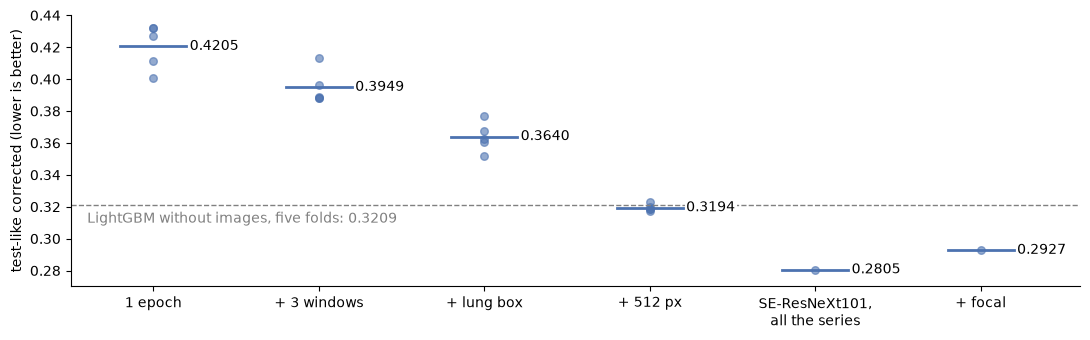

In [14]:
steps = {"1 epoch": A, "+ 3 windows": seeds("s5_w3"), "+ lung box": seeds("s6_lung"), "+ 512 px": seeds("s7_512"), "SE-ResNeXt101,\nall the series": losses["cross-entropy"], "+ focal": losses["focal"]}
fig, ax = plt.subplots(figsize=(11, 3.5))
for x, (name, runs) in enumerate(steps.items()):
    scores = [r[DECIDES] for r in results(runs)]
    ax.scatter([x] * len(scores), scores, s=30, color="#4C72B0", alpha=0.6)
    ax.plot([x - 0.2, x + 0.2], [np.mean(scores)] * 2, color="#4C72B0", lw=2)
    ax.annotate(f"{np.mean(scores):.4f}", (x + 0.22, np.mean(scores)), va="center", bbox=dict(fc="white", ec="none", pad=1), zorder=3)
ax.axhline(TO_BEAT, color="gray", ls="--", lw=1)
ax.annotate(f"LightGBM without images, five folds: {TO_BEAT}", (-0.4, TO_BEAT - 0.004), va="top", color="gray")
ax.set_xticks(range(len(steps)), steps)
ax.set(ylabel="test-like corrected (lower is better)", xlim=(-0.5, 5.6), ylim=(0.27, 0.44))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

**Result:** five folds of SE-ResNeXt101 with focal loss, test-like 0.2908 and corrected 0.2876 over the five folds, against 0.3209 without images. The mean with five folds of ConvNeXt Tiny (cross-entropy) brings the corrected score to 0.2694, and to 0.2715 with the level from the other folds, as on the test set.

**Choices made on fold 0:**

| Question | Chosen | Other options |
|---|---|---|
| series used for screening | 50% | 25%, about 0.06 worse at epoch 1 (seed 1) |
| schedule | 1 epoch, learning rate down to 0: 0.4205 | 4-epoch schedule cut after epoch 1: 0.4021, 1.97 standard errors, under the 2 fixed in advance |
| learning rate | 2.8e-4 | 4e-4: 0.4153 against 0.4111 (seed 1) |
| channels, windows | slice i, three windows: 0.3949 | i: 0.4116; i−2, i, i+2: 0.4232; i−2 ... i+2: 0.4208; mediastinal: 0.4388 (2 seeds) |
| crop | lung box of the series: 0.3640 | body box: 0.3800 (2 seeds) |
| resolution | 512 px, batch 32 × 4: 0.3194 | 256 px: 0.3640 |
| backbones (512 px, seed 1) | SE-ResNeXt101: 0.2805; ConvNeXt Tiny: 0.2876 | MobileViTv2-175: 0.2851 |
| target, loss (B0, 256 px, seed 1) | focal: 0.3107 | cross-entropy: 0.3309; positive series: 0.3134; with q weight: 0.3118; series targets: 0.3242 |
| rare writers (B0, 256 px, seed 1) | kept: 0.3309 | removed: 0.3434 |
| second model, mean with the focal model (512 px, seed 1) | ConvNeXt Tiny, cross-entropy: 0.2709 | SE-ResNeXt101, cross-entropy: 0.2722; MobileViTv2-175: 0.2744 |

The first six rows use B0 on 50% of the series, with 5-seed means unless noted.

**Limits**
- **The folds use focal, but cross-entropy has the better corrected score on the one fold where both exist.** Five folds of cross-entropy were not trained, so the two losses are compared on fold 0 and one seed only.
- Sections 2–6 rest on 50% of the series and on one backbone. Each option was tested once, on the setting of the moment, so interactions are not measured: the epochs and the learning rate were not chosen again at 512 px, and sections 7 and 10 cut a 2-epoch schedule instead of section 3's 1-epoch schedule.
- Sections 7–9 and the five folds rest on one seed each. The three final backbones are closer than the margin.
- 0.0168 comes from the five seeds of one setting at 256 px and is a practical margin. At 512 px the seeds are closer together (std 0.0023), so the same margin is stricter there. Options with 2 seeds are compared with a 5-seed mean, and picking the best of several is slightly optimistic.
- The second model was picked on fold 0's ensemble, so fold 0's gain is slightly optimistic. The two models get equal weights, not tuned.
- The intervals cover the choice of series, not retraining or repeated selection.
- The corrected scores carry a constant fitted on the fold itself, which flatters a model whose level moves between folds. Only section 10 also takes the level from the other folds.
- These scores predict only the slices. The series labels still get the label rates.